# 05 — CLV Analysis and Churn Signal Investigation

**Project:** Repeat Purchase Recovery — Olist E-commerce (Brazil)
**Objective:** Quantify how customer value is distributed across CLV bands, compare repeat vs one-time buyer economics, and evaluate which first-order signals genuinely predict churn.
**Data source:** `data/olist.db` — validated layers through Step 6 (materialised mart tables)
**Observation window:** September 2016 – August 2018

---

### What this notebook answers

| # | Question |
|---|---|
| 1 | How is customer value distributed across CLV bands? |
| 2 | What share of revenue comes from the top bands? |
| 3 | How much more valuable are repeat buyers than one-time buyers? |
| 4 | How common is each churn signal in the customer base? |
| 5 | Which signals actually predict lower repeat rates? |
| 6 | Do flagged customers have lower lifetime revenue? |
| 7 | Which signals are highest priority for intervention? |

> **Baseline for all comparisons:** 90-day right-censored repeat rate = **2.28%** (75,387 eligible customers).


## Setup

Connect to the SQLite database and configure chart styling.

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings("ignore")

DB_PATH = "../data/olist.db"
conn = sqlite3.connect(DB_PATH)

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.facecolor": "white",
})

C_BLUE   = "#2563EB"
C_ORANGE = "#EA580C"
C_GREY   = "#94A3B8"
C_GREEN  = "#16A34A"
C_RED    = "#DC2626"
C_PURPLE = "#7C3AED"

kpi = pd.read_sql("SELECT * FROM executive_kpi_summary", conn).iloc[0]
BASELINE_90D = round(kpi["repeat_rate_90d"] * 100, 2)

print("Connected to:", DB_PATH)
print(f"Baseline 90-day repeat rate : {BASELINE_90D}%")
print(f"Total customers             : {int(kpi['total_customers']):,}")
print(f"Repeat buyers               : {int(kpi['repeat_buyers']):,}  ({BASELINE_90D}%)")


Connected to: ../data/olist.db
Baseline 90-day repeat rate : 2.28%
Total customers             : 93,358
Repeat buyers               : 2,801  (2.28%)


---

## 1. CLV Band Distribution

Each customer is assigned to a CLV band based on their total **observed** revenue across the dataset window. Bands are defined in `customer_clv`:

| Band | Revenue Range |
|------|---------------|
| `no_revenue` | R$0 (1 edge-case customer) |
| `low` | > R$0 and ≤ R$100 |
| `mid` | > R$100 and ≤ R$250 |
| `high` | > R$250 and ≤ R$800 |
| `top` | > R$800 |

> **Important:** These are observed historical revenues, not projected CLV. A customer with one order has CLV equal to that order's value.


In [2]:
clv_dist = pd.read_sql(
    """
    SELECT clv_band, clv_band_order, customers,
           avg_revenue_180d,
           total_lifetime_observed_revenue
    FROM clv_distribution_summary
    WHERE clv_band != 'no_revenue'
    ORDER BY clv_band_order
    """,
    conn,
)

total_cust = clv_dist["customers"].sum()
total_rev  = clv_dist["total_lifetime_observed_revenue"].sum()

clv_dist["pct_customers"] = (clv_dist["customers"] / total_cust * 100).round(1)
clv_dist["pct_revenue"]   = (clv_dist["total_lifetime_observed_revenue"] / total_rev * 100).round(1)

print("CLV Band Summary:")
print(
    clv_dist[["clv_band","customers","pct_customers","avg_revenue_180d",
              "total_lifetime_observed_revenue","pct_revenue"]].to_string(index=False)
)
print(f"\nTotal customers : {total_cust:,}  |  Total revenue : R${total_rev:,.0f}")


CLV Band Summary:
clv_band  customers  pct_customers  avg_revenue_180d  total_lifetime_observed_revenue  pct_revenue
     low      43246           46.3             60.34                       2610359.26         16.9
     mid      39774           42.6            165.24                       6602690.34         42.8
    high       7994            8.6            421.91                       3405976.68         22.1
     top       2343            2.5           1187.35                       2803435.49         18.2

Total customers : 93,357  |  Total revenue : R$15,422,462


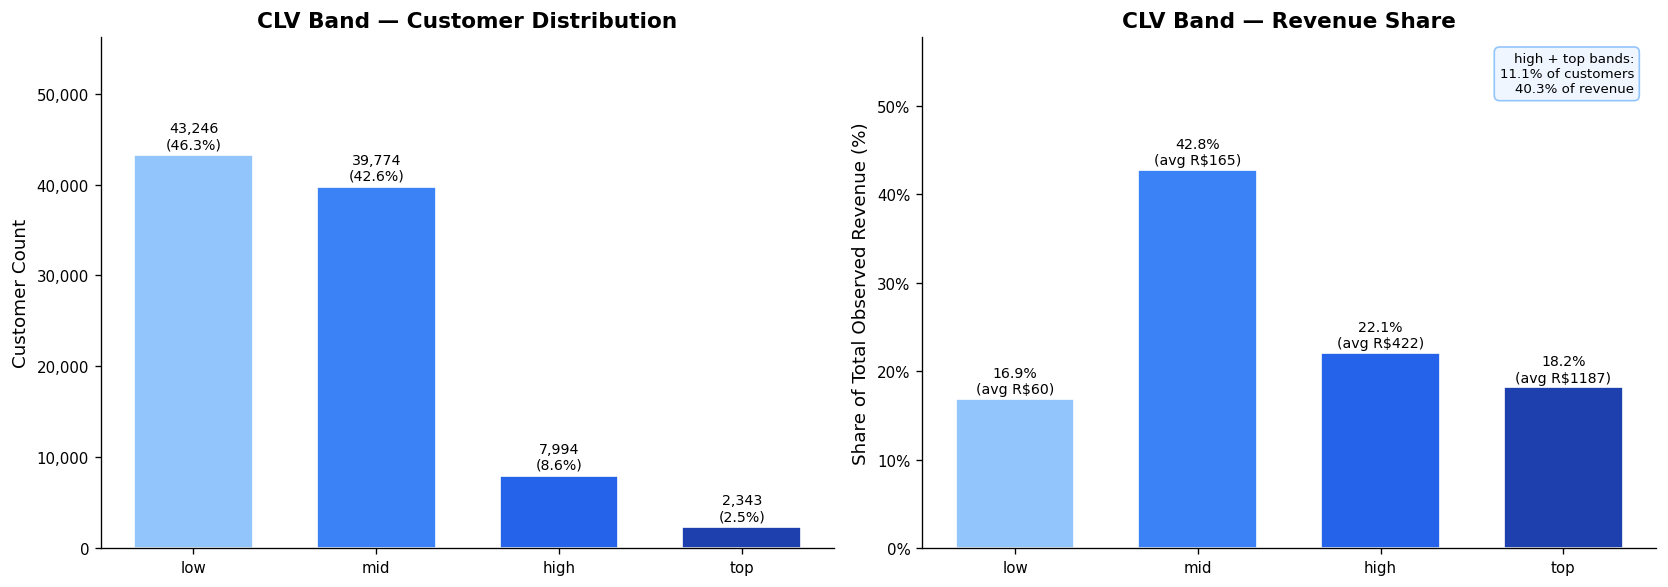

Saved: images/clv_band_distribution.png


In [3]:
band_labels  = clv_dist["clv_band"].tolist()
band_palette = ["#93C5FD", "#3B82F6", "#2563EB", "#1E40AF"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Left: customer count ──────────────────────────────────────────────────────
ax1 = axes[0]
bars1 = ax1.bar(band_labels, clv_dist["customers"],
                color=band_palette, edgecolor="white", width=0.65)
for bar, (_, row) in zip(bars1, clv_dist.iterrows()):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 400,
        f"{row.customers:,}\n({row.pct_customers:.1f}%)",
        ha="center", va="bottom", fontsize=8.5,
    )
ax1.set_ylabel("Customer Count")
ax1.set_title("CLV Band — Customer Distribution")
ax1.set_ylim(0, clv_dist["customers"].max() * 1.3)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

# ── Right: revenue share ──────────────────────────────────────────────────────
ax2 = axes[1]
bars2 = ax2.bar(band_labels, clv_dist["pct_revenue"],
                color=band_palette, edgecolor="white", width=0.65)
for bar, (_, row) in zip(bars2, clv_dist.iterrows()):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{row.pct_revenue:.1f}%\n(avg R${row.avg_revenue_180d:.0f})",
        ha="center", va="bottom", fontsize=8.5,
    )
ax2.set_ylabel("Share of Total Observed Revenue (%)")
ax2.set_title("CLV Band — Revenue Share")
ax2.set_ylim(0, clv_dist["pct_revenue"].max() * 1.35)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}%"))

top_rev  = clv_dist[clv_dist["clv_band"].isin(["high","top"])]["pct_revenue"].sum()
top_cust = clv_dist[clv_dist["clv_band"].isin(["high","top"])]["pct_customers"].sum()
ax2.text(0.97, 0.97,
    f"high + top bands:\n{top_cust:.1f}% of customers\n{top_rev:.1f}% of revenue",
    transform=ax2.transAxes, ha="right", va="top", fontsize=8,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#EFF6FF", edgecolor="#93C5FD"),
)

plt.tight_layout()
plt.savefig("../images/clv_band_distribution.png", bbox_inches="tight")
plt.show()
print("Saved: images/clv_band_distribution.png")


**Interpretation:**

| Band | Customers | % of Total | Revenue Share | Avg Revenue |
|------|-----------|------------|---------------|-------------|
| low  | 43,246    | 46.3%      | 16.9%         | R$60        |
| mid  | 39,774    | 42.6%      | 42.8%         | R$165       |
| high | 7,994     | 8.6%       | 22.1%         | R$422       |
| top  | 2,343     | 2.5%       | 18.2%         | R$1,187     |

- The **top 11.1% of customers** (high + top) account for ~40% of all revenue.
- The **mid band** drives the most total revenue purely through volume (39,774 customers).
- The **low band** holds 46% of all customers but generates only 17% of revenue — predominantly one-time, single-transaction buyers.
- Top-band average revenue (R$1,187) is **20× the low-band average** (R$60).

**Business signal:** Nudging mid-band customers into a second purchase — shifting them toward the high band — is the highest-volume, highest-impact revenue upgrade available.


---

## 2. Repeat Buyers vs One-Time Buyers

This section compares the two fundamental customer segments on revenue contribution and first-order experience. Source: `repeat_vs_one_time_summary` (dashboard view built from customer marts).

> **Note:** One-time buyer 90d and 180d revenue equals first-order value — they never returned, so every subsequent window is zero.


In [4]:
rvo = pd.read_sql("SELECT * FROM repeat_vs_one_time_summary", conn)
print("Repeat vs One-Time Summary:")
print(rvo.to_string(index=False))


Repeat vs One-Time Summary:
    buyer_type  customers  avg_revenue_90d  avg_revenue_180d  avg_first_order_value  avg_first_review_score  avg_first_delivery_days
  repeat_buyer       2801           253.10            277.88                 145.99                    4.20                     12.4
one_time_buyer      90557           160.76            160.76                 160.76                    4.15                     12.5


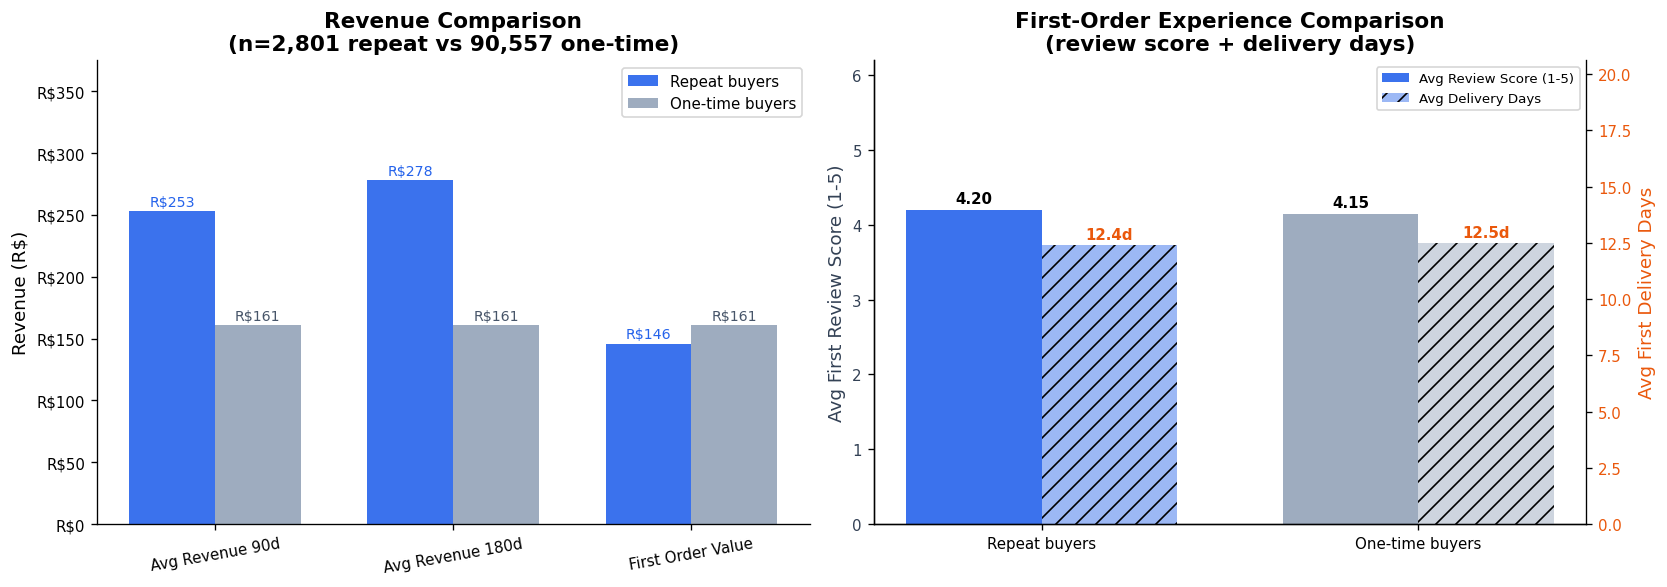

Saved: images/repeat_vs_onetime_comparison.png


In [5]:
repeat_row  = rvo[rvo["buyer_type"] == "repeat_buyer"].iloc[0]
onetime_row = rvo[rvo["buyer_type"] == "one_time_buyer"].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x    = np.arange(3)
bw   = 0.36
rev_labels = ["Avg Revenue 90d", "Avg Revenue 180d", "First Order Value"]

rev_rep = [repeat_row.avg_revenue_90d, repeat_row.avg_revenue_180d, repeat_row.avg_first_order_value]
rev_ot  = [onetime_row.avg_revenue_90d, onetime_row.avg_revenue_180d, onetime_row.avg_first_order_value]

# ── Left: revenue comparison ──────────────────────────────────────────────────
ax1 = axes[0]
b1 = ax1.bar(x - bw / 2, rev_rep,  width=bw, color=C_BLUE, alpha=0.9, label="Repeat buyers")
b2 = ax1.bar(x + bw / 2, rev_ot,   width=bw, color=C_GREY, alpha=0.9, label="One-time buyers")
for bar, val in zip(b1, rev_rep):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
             f"R${val:.0f}", ha="center", va="bottom", fontsize=8.5, color=C_BLUE)
for bar, val in zip(b2, rev_ot):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
             f"R${val:.0f}", ha="center", va="bottom", fontsize=8.5, color="#475569")
ax1.set_xticks(x)
ax1.set_xticklabels(rev_labels, rotation=10)
ax1.set_ylabel("Revenue (R$)")
ax1.set_title(
    f"Revenue Comparison\n"
    f"(n={int(repeat_row.customers):,} repeat vs {int(onetime_row.customers):,} one-time)"
)
ax1.set_ylim(0, max(rev_rep) * 1.35)
ax1.legend(fontsize=9)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"R${int(x)}"))

# ── Right: first-order experience ────────────────────────────────────────────
ax2 = axes[1]
grp_labels = ["Repeat buyers", "One-time buyers"]
xpos = np.arange(2)
scores = [repeat_row.avg_first_review_score, onetime_row.avg_first_review_score]
days   = [repeat_row.avg_first_delivery_days, onetime_row.avg_first_delivery_days]

b3 = ax2.bar(xpos - bw / 2, scores, width=bw, color=[C_BLUE, C_GREY],
             alpha=0.9, label="Avg Review Score (1-5)")
ax2.set_ylabel("Avg First Review Score (1-5)", color="#334155")
ax2.set_ylim(0, 6.2)
ax2.tick_params(axis="y", labelcolor="#334155")

ax3 = ax2.twinx()
b4 = ax3.bar(xpos + bw / 2, days, width=bw, color=[C_BLUE, C_GREY],
             alpha=0.45, hatch="//", label="Avg Delivery Days")
ax3.set_ylabel("Avg First Delivery Days", color=C_ORANGE)
ax3.tick_params(axis="y", labelcolor=C_ORANGE)
ax3.spines["right"].set_visible(True)
ax3.spines["top"].set_visible(False)
ax3.set_ylim(0, max(days) * 1.65)

for bar, val in zip(b3, scores):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
             f"{val:.2f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
for bar, val in zip(b4, days):
    ax3.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.12,
             f"{val:.1f}d", ha="center", va="bottom", fontsize=9,
             fontweight="bold", color=C_ORANGE)

ax2.set_xticks(xpos)
ax2.set_xticklabels(grp_labels)
ax2.set_title("First-Order Experience Comparison\n(review score + delivery days)")
l1, n1 = ax2.get_legend_handles_labels()
l2, n2 = ax3.get_legend_handles_labels()
ax2.legend(l1 + l2, n1 + n2, fontsize=8, loc="upper right")

plt.tight_layout()
plt.savefig("../images/repeat_vs_onetime_comparison.png", bbox_inches="tight")
plt.show()
print("Saved: images/repeat_vs_onetime_comparison.png")


**Interpretation:**

| Metric | Repeat Buyers (2,801) | One-Time Buyers (90,557) |
|--------|-----------------------|--------------------------|
| Avg Revenue 90d  | R$253 | R$161 |
| Avg Revenue 180d | R$278 | R$161 |
| First Order Value | R$146 | R$161 |
| Avg Review Score | 4.20  | 4.15  |
| Avg Delivery Days | 12.4d | 12.5d |

Key findings:
1. **Repeat buyers generate 73% more revenue per customer** (R$278 vs R$161 over 180 days).
2. **Repeat buyers' first order value is lower** (R$146 vs R$161) — exploratory, smaller first purchases predict return behaviour better than big first orders.
3. **First-order experience is nearly identical** — review scores and delivery days are statistically indistinguishable. The quality of the first experience does not explain who returns.
4. **One-time buyer 90d and 180d revenue are identical** (R$161) — confirming they never placed a second order.


---

## 3. Churn Signal Prevalence

The `churn_signal_mart` assigns 7 binary flags to each customer based on first-order observables:

| Signal | Definition |
|--------|------------|
| `no_repeat_within_90d` | Did not place a second order within 90 days — the **outcome variable** |
| `single_item_first_order` | First order contained only 1 item |
| `low_first_order_value` | First order total < R$50 |
| `high_freight_ratio` | Freight cost > 50% of item price on first order |
| `low_first_review_score` | First review was 1 or 2 stars |
| `delayed_first_delivery` | First delivery arrived after the estimated date |
| `missing_review` | No review submitted on first order |

> `no_repeat_within_90d` is excluded from predictor analysis — it directly **is** the churn outcome. The other 6 flags are potential first-order predictors.


In [6]:
churn_prev = pd.read_sql(
    """
    SELECT signal_name,
           flagged_customers,
           total_customers,
           ROUND(flagged_rate * 100, 2) AS flagged_rate_pct
    FROM churn_signal_summary
    ORDER BY flagged_rate DESC
    """,
    conn,
)
print("Churn Signal Prevalence:")
print(churn_prev.to_string(index=False))


Churn Signal Prevalence:
            signal_name  flagged_customers  total_customers  flagged_rate_pct
   no_repeat_within_90d              73671            75387             97.72
single_item_first_order              84151            93358             90.14
  low_first_order_value              15916            93357             17.05
     high_freight_ratio              14742            93358             15.79
 low_first_review_score              11913            92743             12.85
 delayed_first_delivery               7428            93350              7.96
         missing_review                615            93358              0.66


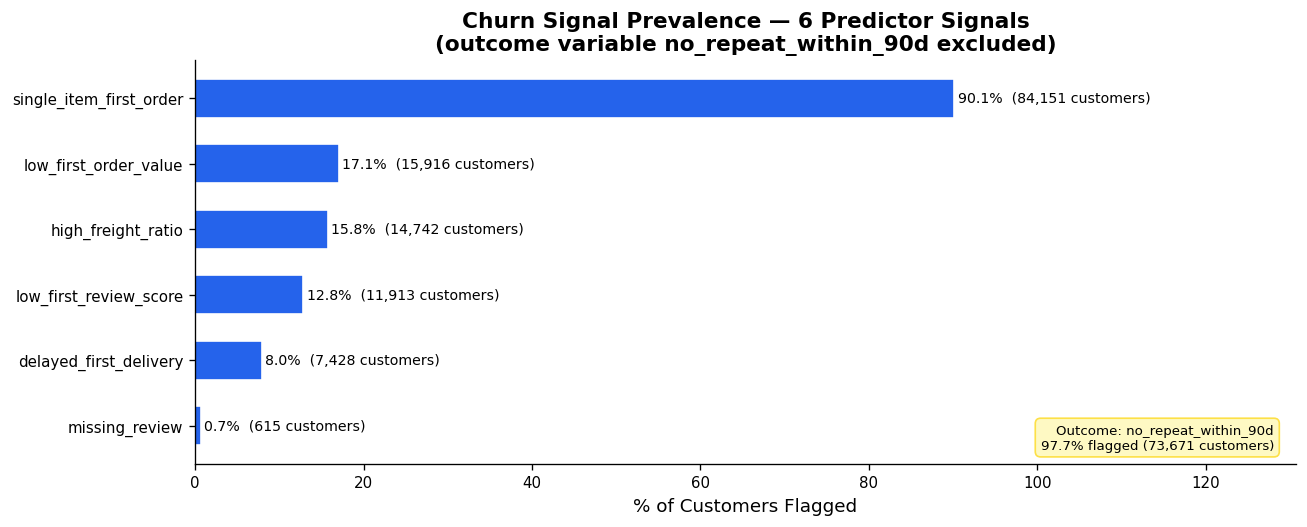

Saved: images/churn_signal_prevalence.png


In [7]:
outcome_row   = churn_prev[churn_prev["signal_name"] == "no_repeat_within_90d"].iloc[0]
predictor_df  = churn_prev[churn_prev["signal_name"] != "no_repeat_within_90d"].copy()
predictor_df  = predictor_df.sort_values("flagged_rate_pct")

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.barh(
    predictor_df["signal_name"], predictor_df["flagged_rate_pct"],
    color=C_BLUE, height=0.6, edgecolor="white",
)
for bar, (_, row) in zip(bars, predictor_df.iterrows()):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{row.flagged_rate_pct:.1f}%  ({row.flagged_customers:,} customers)",
        va="center", fontsize=8.5,
    )
ax.set_xlabel("% of Customers Flagged")
ax.set_title(
    "Churn Signal Prevalence — 6 Predictor Signals\n"
    "(outcome variable no_repeat_within_90d excluded)"
)
ax.set_xlim(0, predictor_df["flagged_rate_pct"].max() * 1.45)
ax.text(
    0.98, 0.03,
    f"Outcome: no_repeat_within_90d\n{outcome_row.flagged_rate_pct:.1f}% flagged ({int(outcome_row.flagged_customers):,} customers)",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=8,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#FEF9C3", edgecolor="#FDE047"),
)
plt.tight_layout()
plt.savefig("../images/churn_signal_prevalence.png", bbox_inches="tight")
plt.show()
print("Saved: images/churn_signal_prevalence.png")


**Interpretation:**

| Signal | Prevalence | Flagged Customers |
|--------|-----------|-------------------|
| single_item_first_order | **90.1%** | 84,151 |
| low_first_order_value   | 17.1%    | 15,916 |
| high_freight_ratio      | 15.8%    | 14,742 |
| low_first_review_score  | 12.9%    | 11,913 |
| delayed_first_delivery  | 8.0%     | 7,428  |
| missing_review          | 0.7%     | 615    |

`single_item_first_order` is not a rare risk flag — it is the **default behaviour** on this platform. 9 in 10 customers bought only one item on their first order.

`missing_review` (0.7%) is too rare to be a meaningful targeting signal.


---

## 4. Repeat Rate by Churn Signal

For each of the 6 predictor signals, this section computes the 90-day repeat rate for **flagged** vs **not-flagged** customers. Right-censored customers (NULL in `repeat_within_90d`) are excluded from all rate calculations.

A signal is a useful churn predictor if flagged customers show a meaningfully lower repeat rate.


In [8]:
FLAG_COLS = {
    "low_first_review_score_flag" : "Low Review Score",
    "delayed_first_delivery_flag" : "Delayed Delivery",
    "single_item_first_order_flag": "Single-Item Order",
    "low_first_order_value_flag"  : "Low Order Value",
    "high_freight_ratio_flag"     : "High Freight Ratio",
    "missing_review_flag"         : "Missing Review",
}

rate_rows = []
for col, label in FLAG_COLS.items():
    q = f"""
    SELECT
        c.{col}                                                    AS flagged,
        COUNT(*)                                                   AS customers,
        ROUND(AVG(CAST(r.repeat_within_90d AS REAL)) * 100, 2)    AS repeat_rate_90d
    FROM csm_mat c
    JOIN crsm_mat r ON c.customer_unique_id = r.customer_unique_id
    WHERE c.{col} IS NOT NULL
    GROUP BY c.{col}
    ORDER BY c.{col}
    """
    for _, row in pd.read_sql(q, conn).iterrows():
        rate_rows.append({
            "signal"          : label,
            "flagged"         : int(row["flagged"]),
            "customers"       : int(row["customers"]),
            "repeat_rate_90d" : float(row["repeat_rate_90d"]),
        })

signal_rates = pd.DataFrame(rate_rows)
print("90-day repeat rate by signal (flagged=1: flag triggered; flagged=0: not triggered):")
print(signal_rates.to_string(index=False))


90-day repeat rate by signal (flagged=1: flag triggered; flagged=0: not triggered):
            signal  flagged  customers  repeat_rate_90d
  Low Review Score        0      80830             2.28
  Low Review Score        1      11913             2.28
  Delayed Delivery        0      85922             2.30
  Delayed Delivery        1       7428             2.05
 Single-Item Order        0       9207             3.40
 Single-Item Order        1      84151             2.15
   Low Order Value        0      77441             2.24
   Low Order Value        1      15916             2.46
High Freight Ratio        0      78616             2.20
High Freight Ratio        1      14742             2.69
    Missing Review        0      92743             2.28
    Missing Review        1        615             2.25


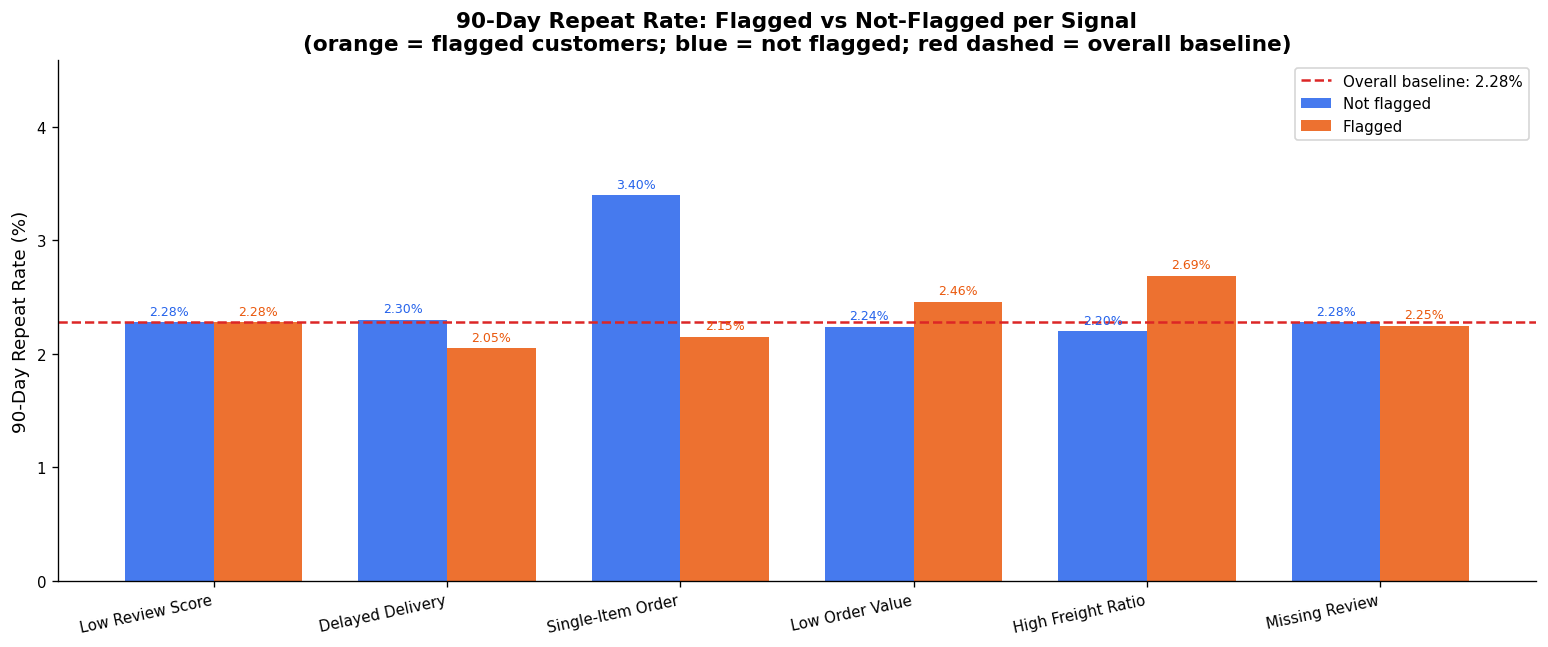

Saved: images/churn_signal_repeat_rate.png


In [9]:
BASELINE = BASELINE_90D

sig_labels = list(FLAG_COLS.values())
x  = np.arange(len(sig_labels))
bw = 0.38

rates_0, rates_1 = [], []
for sig in sig_labels:
    sub = signal_rates[signal_rates["signal"] == sig]
    r0  = sub[sub["flagged"] == 0]["repeat_rate_90d"].values
    r1  = sub[sub["flagged"] == 1]["repeat_rate_90d"].values
    rates_0.append(float(r0[0]) if len(r0) else np.nan)
    rates_1.append(float(r1[0]) if len(r1) else np.nan)

fig, ax = plt.subplots(figsize=(13, 5.5))
b0 = ax.bar(x - bw / 2, rates_0, width=bw, color=C_BLUE,   alpha=0.85, label="Not flagged")
b1 = ax.bar(x + bw / 2, rates_1, width=bw, color=C_ORANGE, alpha=0.85, label="Flagged")

ax.axhline(BASELINE, color=C_RED, linestyle="--", linewidth=1.5,
           label=f"Overall baseline: {BASELINE}%")

for bar, val in zip(b0, rates_0):
    if not np.isnan(val):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.04,
                f"{val:.2f}%", ha="center", va="bottom", fontsize=7.5, color=C_BLUE)
for bar, val in zip(b1, rates_1):
    if not np.isnan(val):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.04,
                f"{val:.2f}%", ha="center", va="bottom", fontsize=7.5, color=C_ORANGE)

ax.set_xticks(x)
ax.set_xticklabels(sig_labels, rotation=12, ha="right")
ax.set_ylabel("90-Day Repeat Rate (%)")
ax.set_title(
    "90-Day Repeat Rate: Flagged vs Not-Flagged per Signal\n"
    "(orange = flagged customers; blue = not flagged; red dashed = overall baseline)"
)
ax.set_ylim(0, max(r for r in rates_0 if not np.isnan(r)) * 1.35)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("../images/churn_signal_repeat_rate.png", bbox_inches="tight")
plt.show()
print("Saved: images/churn_signal_repeat_rate.png")


**Interpretation:**

| Signal | Not-Flagged Rate | Flagged Rate | Impact (pp) |
|--------|-----------------|--------------|-------------|
| Single-Item Order | 3.40% | 2.15% | **-1.25pp** |
| Delayed Delivery  | 2.30% | 2.05% | -0.25pp     |
| Low Order Value   | 2.24% | 2.46% | +0.22pp (counter-intuitive) |
| High Freight Ratio| 2.20% | 2.69% | +0.49pp (counter-intuitive) |
| Low Review Score  | 2.28% | 2.28% | 0.00pp (no signal) |
| Missing Review    | 2.28% | 2.25% | -0.03pp (no signal) |

**Only 2 signals show genuine negative impact:**
- **Single-item order (-1.25pp)** — largest effect, affects 90% of customers.
- **Delayed delivery (-0.25pp)** — modest but real, 7,428 customers affected.

**Counter-intuitive positives:** Low-value and high-freight customers return more often. These tend to be habitual, small-basket shoppers — affordable items, frequent repurchase behaviour. Consistent with NB04 findings.

**Non-signals:** Low review score and missing review have no measurable impact on repeat rate. Do not use them to target at-risk customers.


---

## 5. Revenue Differences by Churn Signal

Beyond repeat rate, do flagged customers have lower lifetime revenue? This matters for prioritising intervention budget — a signal affecting high-value customers warrants more investment than one affecting low-value customers.


In [10]:
rev_rows = []
for col, label in FLAG_COLS.items():
    q = f"""
    SELECT
        c.{col}                                               AS flagged,
        COUNT(*)                                              AS customers,
        ROUND(AVG(cl.lifetime_observed_revenue), 2)           AS avg_lifetime_rev,
        ROUND(AVG(cl.revenue_90d), 2)                         AS avg_rev_90d
    FROM csm_mat c
    JOIN clv_mat cl ON c.customer_unique_id = cl.customer_unique_id
    WHERE c.{col} IS NOT NULL
    GROUP BY c.{col}
    ORDER BY c.{col}
    """
    for _, row in pd.read_sql(q, conn).iterrows():
        rev_rows.append({
            "signal"          : label,
            "flagged"         : int(row["flagged"]),
            "customers"       : int(row["customers"]),
            "avg_lifetime_rev": float(row["avg_lifetime_rev"]),
        })

signal_rev = pd.DataFrame(rev_rows)
print("Avg lifetime revenue by signal:")
print(signal_rev.to_string(index=False))


Avg lifetime revenue by signal:
            signal  flagged  customers  avg_lifetime_rev
  Low Review Score        0      80830            160.78
  Low Review Score        1      11913            193.14
  Delayed Delivery        0      85922            164.08
  Delayed Delivery        1       7428            178.10
 Single-Item Order        0       9207            257.44
 Single-Item Order        1      84151            155.10
   Low Order Value        0      77441            190.82
   Low Order Value        1      15916             40.52
High Freight Ratio        0      78616            183.82
High Freight Ratio        1      14742             65.90
    Missing Review        0      92743            164.94
    Missing Review        1        615            204.59


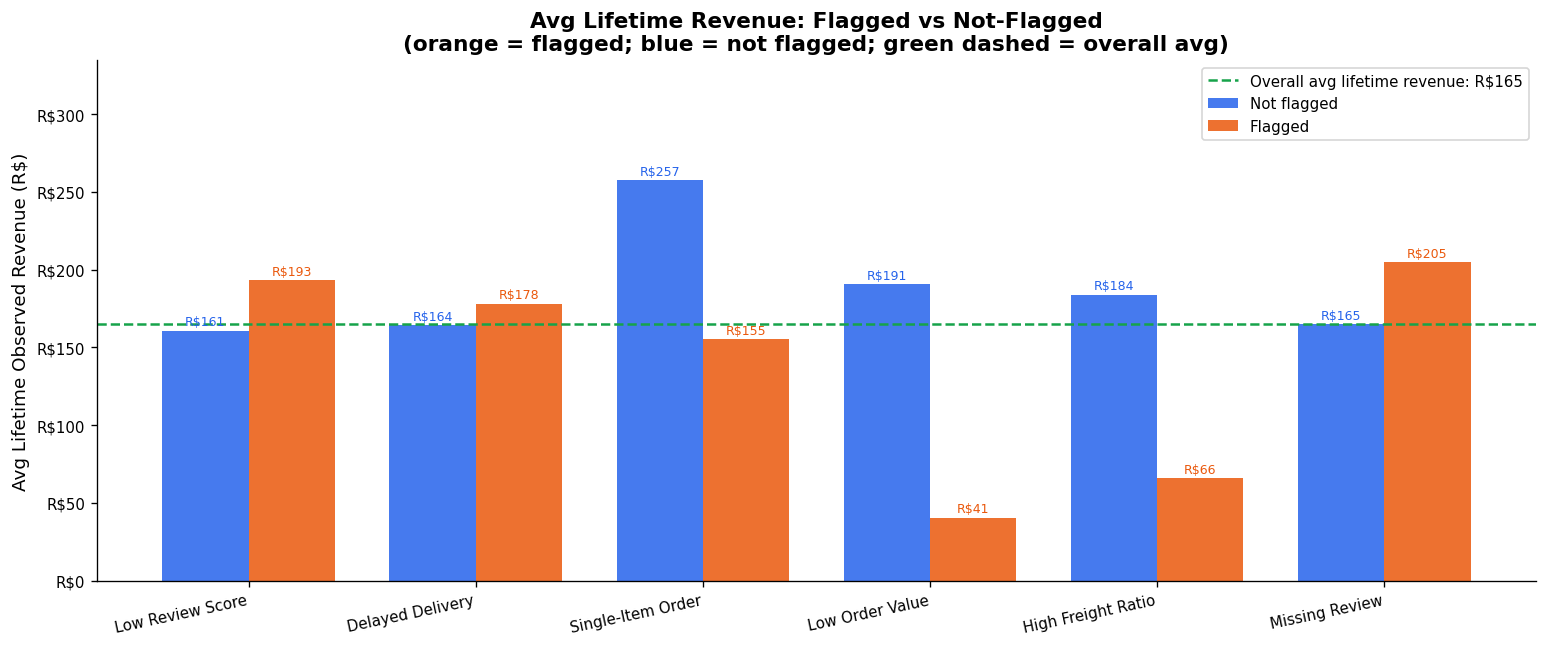

Saved: images/churn_signal_revenue.png


In [11]:
rev_0, rev_1 = [], []
for sig in sig_labels:
    sub = signal_rev[signal_rev["signal"] == sig]
    v0  = sub[sub["flagged"] == 0]["avg_lifetime_rev"].values
    v1  = sub[sub["flagged"] == 1]["avg_lifetime_rev"].values
    rev_0.append(float(v0[0]) if len(v0) else np.nan)
    rev_1.append(float(v1[0]) if len(v1) else np.nan)

overall_avg = float(pd.read_sql(
    "SELECT ROUND(AVG(lifetime_observed_revenue),2) FROM clv_mat", conn
).iloc[0, 0])

fig, ax = plt.subplots(figsize=(13, 5.5))
b0 = ax.bar(x - bw / 2, rev_0, width=bw, color=C_BLUE,   alpha=0.85, label="Not flagged")
b1 = ax.bar(x + bw / 2, rev_1, width=bw, color=C_ORANGE, alpha=0.85, label="Flagged")

ax.axhline(overall_avg, color=C_GREEN, linestyle="--", linewidth=1.5,
           label=f"Overall avg lifetime revenue: R${overall_avg:.0f}")

for bar, val in zip(b0, rev_0):
    if not np.isnan(val):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
                f"R${val:.0f}", ha="center", va="bottom", fontsize=7.5, color=C_BLUE)
for bar, val in zip(b1, rev_1):
    if not np.isnan(val):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
                f"R${val:.0f}", ha="center", va="bottom", fontsize=7.5, color=C_ORANGE)

ax.set_xticks(x)
ax.set_xticklabels(sig_labels, rotation=12, ha="right")
ax.set_ylabel("Avg Lifetime Observed Revenue (R$)")
ax.set_title(
    "Avg Lifetime Revenue: Flagged vs Not-Flagged\n"
    "(orange = flagged; blue = not flagged; green dashed = overall avg)"
)
ax.set_ylim(0, max(v for v in rev_0 if not np.isnan(v)) * 1.3)
ax.legend(fontsize=9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"R${int(v)}"))

plt.tight_layout()
plt.savefig("../images/churn_signal_revenue.png", bbox_inches="tight")
plt.show()
print("Saved: images/churn_signal_revenue.png")


**Interpretation:**

| Signal | Not-Flagged Avg Revenue | Flagged Avg Revenue | Revenue Gap |
|--------|------------------------|---------------------|-------------|
| Single-Item Order | R$257 | R$155 | **-R$102** |
| Low Order Value   | R$191 | R$41  | **-R$150** |
| High Freight Ratio| R$184 | R$66  | **-R$118** |
| Delayed Delivery  | R$164 | R$178 | +R$14      |
| Low Review Score  | R$161 | R$193 | +R$32      |
| Missing Review    | R$165 | R$205 | +R$40      |

Revenue patterns diverge from repeat-rate patterns:
- **Single-item buyers have lower lifetime revenue** (R$155 vs R$257) — both lower repeat rates and smaller order sizes compound the gap.
- **Low order value and high freight ratio flags** are lower revenue by definition (small first orders), but their higher repeat rates show they are habitual buyers making frequent small purchases.
- **Delayed delivery and low review score customers have HIGHER average revenue** — these are customers who ordered expensive items. A late delivery or bad experience on a high-value order is a costly retention risk worth addressing.


---

## 6. Churn Signal Priority Matrix

This section combines all three dimensions — prevalence, repeat-rate impact, and revenue context — into a single decision framework.

- **X-axis:** Signal prevalence (% of customers flagged)
- **Y-axis:** Repeat rate impact (flagged rate − not-flagged rate, in pp). Negative = churn risk.
- **Bubble size:** Total flagged customers
- **Colour:** Red = churn risk (negative pp), Green = counter-intuitive positive, Grey = no signal


In [12]:
priority_rows = []
for sig in sig_labels:
    sub_r = signal_rates[signal_rates["signal"] == sig]
    sub_v = signal_rev[signal_rev["signal"] == sig]
    r0 = sub_r[sub_r["flagged"] == 0]["repeat_rate_90d"].values
    r1 = sub_r[sub_r["flagged"] == 1]["repeat_rate_90d"].values
    v1 = sub_v[sub_v["flagged"] == 1]["avg_lifetime_rev"].values
    n_flagged = int(sub_r[sub_r["flagged"] == 1]["customers"].values[0])
    n_total   = int(sub_r["customers"].sum())
    priority_rows.append({
        "signal"           : sig,
        "prevalence_pct"   : round(n_flagged / n_total * 100, 2),
        "flagged_n"        : n_flagged,
        "rate_not_flagged" : float(r0[0]) if len(r0) else np.nan,
        "rate_flagged"     : float(r1[0]) if len(r1) else np.nan,
        "rate_delta_pp"    : round(float(r1[0]) - float(r0[0]), 2) if len(r0) and len(r1) else np.nan,
        "rev_flagged"      : float(v1[0]) if len(v1) else np.nan,
    })

priority_df = pd.DataFrame(priority_rows).sort_values("rate_delta_pp")
print("Signal Priority Summary (sorted by repeat rate impact):")
print(
    priority_df[["signal","prevalence_pct","flagged_n",
                 "rate_not_flagged","rate_flagged","rate_delta_pp","rev_flagged"]].to_string(index=False)
)


Signal Priority Summary (sorted by repeat rate impact):
            signal  prevalence_pct  flagged_n  rate_not_flagged  rate_flagged  rate_delta_pp  rev_flagged
 Single-Item Order           90.14      84151              3.40          2.15          -1.25       155.10
  Delayed Delivery            7.96       7428              2.30          2.05          -0.25       178.10
    Missing Review            0.66        615              2.28          2.25          -0.03       204.59
  Low Review Score           12.85      11913              2.28          2.28           0.00       193.14
   Low Order Value           17.05      15916              2.24          2.46           0.22        40.52
High Freight Ratio           15.79      14742              2.20          2.69           0.49        65.90


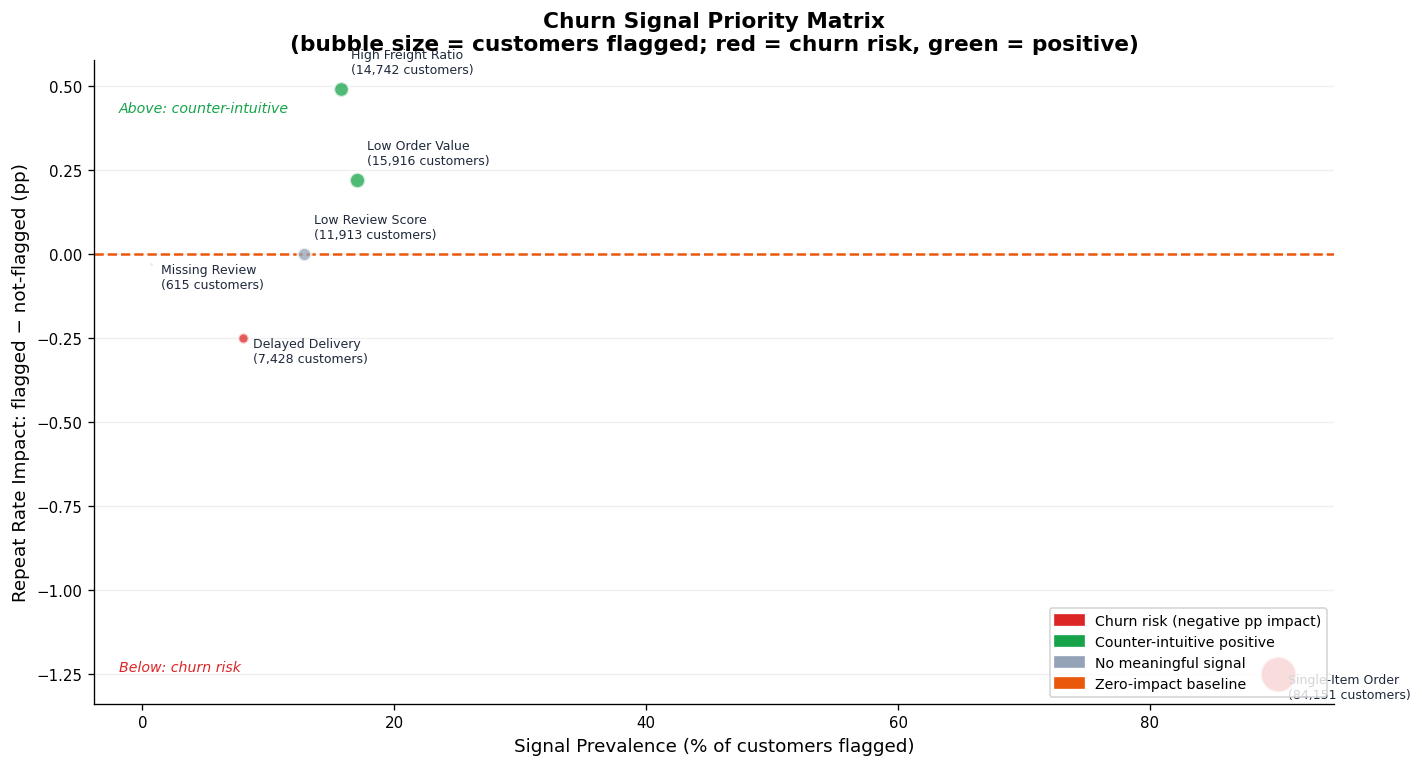

Saved: images/churn_signal_priority_matrix.png


In [13]:
fig, ax = plt.subplots(figsize=(12, 6.5))

for _, row in priority_df.iterrows():
    xp     = row["prevalence_pct"]
    yp     = row["rate_delta_pp"]
    bsize  = row["flagged_n"] / 180
    if row["rate_delta_pp"] < -0.1:
        color = C_RED
    elif row["rate_delta_pp"] > 0.1:
        color = C_GREEN
    else:
        color = C_GREY

    ax.scatter(xp, yp, s=bsize, c=color, alpha=0.75,
               edgecolors="white", linewidths=1.5, zorder=3)
    y_offset = 10 if yp >= 0 else -14
    ax.annotate(
        f"{row['signal']}\n({row['flagged_n']:,} customers)",
        (xp, yp),
        textcoords="offset points",
        xytext=(6, y_offset),
        fontsize=7.5, color="#1E293B",
    )

ax.axhline(0, color=C_ORANGE, linestyle="--", linewidth=1.5,
           label="Zero impact on repeat rate", zorder=2)

legend_elements = [
    mpatches.Patch(color=C_RED,   label="Churn risk (negative pp impact)"),
    mpatches.Patch(color=C_GREEN, label="Counter-intuitive positive"),
    mpatches.Patch(color=C_GREY,  label="No meaningful signal"),
    mpatches.Patch(color=C_ORANGE, label="Zero-impact baseline"),
]
ax.legend(handles=legend_elements, fontsize=8.5, loc="lower right")

ax.text(0.02, 0.05, "Below: churn risk", transform=ax.transAxes,
        fontsize=8.5, color=C_RED, fontstyle="italic")
ax.text(0.02, 0.92, "Above: counter-intuitive", transform=ax.transAxes,
        fontsize=8.5, color=C_GREEN, fontstyle="italic")

ax.set_xlabel("Signal Prevalence (% of customers flagged)", fontsize=11)
ax.set_ylabel("Repeat Rate Impact: flagged − not-flagged (pp)", fontsize=11)
ax.set_title(
    "Churn Signal Priority Matrix\n"
    "(bubble size = customers flagged; red = churn risk, green = positive)"
)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig("../images/churn_signal_priority_matrix.png", bbox_inches="tight")
plt.show()
print("Saved: images/churn_signal_priority_matrix.png")


**Reading the priority matrix:**

- **Bottom-right** (high prevalence, negative impact) → `single_item_first_order`: affects 90% of customers, -1.25pp impact. **Highest priority.**
- **Bottom-left** (low prevalence, negative impact) → `delayed_first_delivery`: 7,428 customers, -0.25pp. **Targeted recovery play.**
- **Top region** (positive impact) → `high_freight_ratio` and `low_order_value`: counter-intuitive. These are NOT churn risks.
- **Centre** (near-zero impact) → `low_review_score` and `missing_review`: flat signals, not useful for targeting.


---

## 7. Business Implications


In [14]:
# Cross-reference CLV band with repeat rate
clv_repeat = pd.read_sql(
    """
    SELECT
        cl.clv_band,
        COUNT(*)                                               AS customers,
        ROUND(AVG(cl.lifetime_observed_revenue), 2)            AS avg_lifetime_rev,
        ROUND(SUM(cl.lifetime_observed_revenue) /
              (SELECT SUM(lifetime_observed_revenue) FROM clv_mat) * 100, 1)
                                                               AS revenue_share_pct,
        ROUND(AVG(CAST(r.repeat_within_90d AS REAL)) * 100, 2) AS repeat_rate_90d
    FROM clv_mat cl
    JOIN crsm_mat r ON cl.customer_unique_id = r.customer_unique_id
    GROUP BY cl.clv_band
    ORDER BY
        CASE cl.clv_band
            WHEN 'no_revenue' THEN 0
            WHEN 'low'        THEN 1
            WHEN 'mid'        THEN 2
            WHEN 'high'       THEN 3
            WHEN 'top'        THEN 4
        END
    """,
    conn,
)
print("CLV band × repeat rate cross-reference:")
print(clv_repeat.to_string(index=False))


CLV band × repeat rate cross-reference:
  clv_band  customers  avg_lifetime_rev  revenue_share_pct  repeat_rate_90d
no_revenue          1              0.00                0.0             0.00
       low      43246             60.36               16.9             0.51
       mid      39774            166.01               42.8             2.98
      high       7994            426.07               22.1             7.05
       top       2343           1196.52               18.2             6.36


### Key Business Implications

---

**1. The mid-to-high CLV band upgrade is the most attainable revenue growth path**

39,774 mid-band customers (avg R$165) account for 43% of total revenue. Mid-band customers who place a second order shift into the high band (avg R$422 — a 2.6× increase). Converting even 3% of mid-band customers from one-time to repeat (~1,200 customers) would add approximately R$310K in incremental revenue. This upgrade path is more accessible than growing the top band, which would require acquiring premium buyers from scratch.

---

**2. Single-item basket size is the highest-leverage churn signal — and it's actionable at checkout**

90% of customers placed a single-item first order and repeat at 2.15% vs 3.40% for multi-item buyers — a -1.25pp gap at massive scale. Moving even 5% of single-item buyers to 2+ items (~4,200 customers) would raise repeat rates for that cohort by approximately 1pp, yielding ~42 additional repeat buyers per cohort. Recommended tactics: "Frequently bought together" modules, bundle promotions on the checkout page, first-order free-shipping thresholds that incentivise basket top-up.

---

**3. Delayed delivery requires targeted service recovery — the affected segment is well-defined**

7,428 customers received late deliveries and repeat at 2.05% vs 2.30% for on-time customers. This is a ~0.25pp deficit on a clearly identifiable group. An automated service recovery workflow (triggered by delivery date miss: apology email + R$15–R$20 voucher) would cost approximately R$110K–R$150K in voucher value but could recover the ~19 expected lost repeat buyers per cohort at a meaningful LTV multiple.

---

**4. Low review score is not a churn predictor — but it identifies high-value recovery targets**

Customers with 1–2 star reviews repeat at the same rate as satisfied customers (2.28%), but have meaningfully higher average lifetime revenue (R$193 vs R$161). These are high-spending customers who had a bad first experience. Service recovery is justified for quality reasons — not because they would churn otherwise, but because an unresolved bad experience increases the risk of churn on their second visit.

---

**5. Counter-intuitive signals reveal a valuable micro-segment: the habitual small-basket buyer**

High-freight-ratio and low-order-value customers repeat at above-baseline rates (2.69% and 2.46%) despite lower absolute lifetime revenues. These are budget shoppers making frequent small purchases — affordable items where freight is disproportionate (e.g., small household items from distant sellers). Do not flag these customers as at-risk. Instead, study them: understanding what drives their higher engagement could inform platform features that encourage more customers into habitual repurchase patterns.

---

**6. Top-band customers (R$1,187 avg) are invisible until after they self-select**

2,343 customers (2.5% of the base) account for 18% of total revenue, but no current first-order signal reliably identifies them before their second purchase. The existing churn signals are not designed for early identification of high-CLV customers. A next step (outside this notebook's scope) would be to build a first-order feature model — using category, basket size, payment type, and order value — to predict which first-time buyers are likely to become top-band customers, enabling proactive retention investment before they are lost.

---


---

*Next notebook: `06_scenario_analysis.ipynb` — Revenue uplift modelling: quantifying the business impact of converting 1%, 2%, or 5% of one-time buyers to repeat, and which segments offer the highest marginal return.*


In [15]:
conn.close()
print("Database connection closed.")


Database connection closed.
